# What thousands of headline experiments say about A/B testing
## Part 1 of 2: exploration

**When a team runs A/B tests by the thousand, how often is there a real winner, how much of a win is
luck, and what can be learned across tests that no single test can show?**

Data: the Upworthy Research Archive. For each story, Upworthy wrote several "packages" (a headline with
an image and teaser text), showed each visitor one of them at random, and counted the clicks.

The archive is published in parts so that analysts can explore one part and test what they find on
another. This notebook uses only the **exploratory** file. Anything may be tried here. What looks real is
written down as a prediction in `analysis_plan.md` and tested once, in `02_confirmatory.ipynb`, on tests
this notebook never saw.

This notebook is generated from `01_exploratory.py` by `scripts/build_notebooks.py`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "abtests.py").exists())
sys.path.insert(0, str(ROOT / "src"))
import abtests as ab  # noqa: E402
import charts  # noqa: E402

RESULTS, FIGURES = ROOT / "results", ROOT / "figures"
RESULTS.mkdir(exist_ok=True)
pd.set_option("display.width", 170, "display.max_columns", 20, "display.max_colwidth", 95,
              "display.float_format", "{:,.3f}".format)

data = ab.load(ROOT / "data" / "raw" / "upworthy-archive-exploratory-packages-03.12.2020.csv")
tests = ab.test_table(data).join(ab.what_varies(data))
print(f"{len(data):,} packages in {len(tests):,} tests, {data['created_at'].min()[:10]} to {data['created_at'].max()[:10]}")
print(f"a typical package: {data['impressions'].median():,.0f} impressions and {data['clicks'].median():.0f} clicks")
print(f"click rate of a typical test: {100 * tests['ctr'].median():.2f}%")

22,666 packages in 4,873 tests, 2013-01-26 to 2015-04-29
a typical package: 3,122 impressions and 42 clicks
click rate of a typical test: 1.31%


## One test, to fix ideas

Four headlines for the same story, each shown to about the same number of visitors.

In [2]:
example = tests.index[(tests["varies"] == "headline only") & (tests["packages"] == 4)][0]
shown = data.loc[data["test"] == example, ["headline", "impressions", "clicks", "ctr"]].copy()
shown["ctr"] = (100 * shown["ctr"]).round(2)
display(shown.rename(columns={"ctr": "click rate, %"}).reset_index(drop=True))

,headline,impressions,clicks,"click rate, %"
0,"Now For Sale: Daughters, $10,000 Each (If They're Pretty)",2698,92,3.410
1,Why Doesn't This Woman Want Her Daughter To Be Pretty?,2726,94,3.450
2,This Woman's Beef With Prettiness Will Leave You Speechless,2674,108,4.040
3,Why This Woman Thinks Pretty Isn't Enough,2814,73,2.590


## 1. What was being tested?

A test can vary the headline, the image, the teaser text, or several at once. Knowing which matters
later: only tests that vary the headline alone can say anything clean about headlines.

In [3]:
kinds = tests["varies"].value_counts().rename("tests").to_frame()
kinds["share, %"] = (100 * kinds["tests"] / len(tests)).round(1)
display(kinds)

,tests,"share, %"
varies,,
headline only,1801,37.000
image only,1212,24.900
several things,1023,21.000
teaser text only,822,16.900
nothing recorded,15,0.300


## 2. Was the traffic split evenly?

Before believing any test, check that it ran as designed. If visitors were assigned at random with equal
chances, every package in a test should have been shown about equally often. A chi-square test of the
impression counts flags tests where the split is too uneven to be chance (a "sample ratio mismatch").
The threshold is strict (p < 0.001) because with thousands of tests a looser one would flag many by
accident.

In [4]:
uneven = tests["split_p"] < 0.001
spread_of_traffic = data.groupby("test")["impressions"].max() / data.groupby("test")["impressions"].min()
print(f"tests with an uneven split: {uneven.sum():,} of {len(tests):,} ({100 * uneven.mean():.1f}%)")
print(f"expected by chance at this threshold: {0.001 * len(tests):.0f} tests")
print("most-shown package against least-shown package, by test:")
print(spread_of_traffic.quantile([0.5, 0.9, 0.99]).rename({0.5: "  median", 0.9: "  90th percentile", 0.99: "  99th percentile"}).round(3).to_string())

tests with an uneven split: 753 of 4,873 (15.5%)
expected by chance at this threshold: 5 tests
most-shown package against least-shown package, by test:
median            1.046
90th percentile   1.134
99th percentile   1.286


About one test in six did not split its traffic evenly. That does not prove those tests are wrong, but
it means something other than a fair coin decided who saw what: a package added late, one stopped early,
or a fault in delivery. Every headline number below is therefore computed twice, with and without the
flagged tests.

## 3. How often do the packages really differ?

For each test, a chi-square test asks whether all its packages could share one click rate. Tests where
any package would be expected to get fewer than five clicks are left out, because the test is unreliable
there.

Running thousands of tests at the 5% level guarantees false alarms, so two further numbers are needed:

- how many tests still count when the **false discovery rate** is held at 5% (Benjamini-Hochberg): of the
  tests declared different, at most about one in twenty should be a false alarm;
- an estimate of the share of tests in which **nothing truly differs** (Storey's method), read off the
  p-values above 0.5, where real differences hardly ever land.

In [5]:
enough = tests["smallest_expected_clicks"] >= 5
p = tests.loc[enough, "p_value"]
significant = p < 0.05
discoveries = ab.benjamini_hochberg(p)
no_difference = ab.share_with_no_difference(p)
print(f"tests with enough clicks to test: {enough.sum():,} of {len(tests):,}")
print(f"significant at 0.05: {significant.sum():,} ({100 * significant.mean():.1f}%)")
print(f"still counted with the false discovery rate held at 5%: {discoveries.sum():,} ({100 * discoveries.mean():.1f}%)")
print(f"estimated share of tests with no real difference: {100 * no_difference:.1f}%, so about {100 * (1 - no_difference):.0f}% hold a real one")

by_kind = tests[enough].groupby("varies")["p_value"].agg(tests="size", significant=lambda values: 100 * (values < 0.05).mean())
display(by_kind.sort_values("tests", ascending=False).rename(columns={"significant": "significant at 0.05, %"}).round(1))

even = ~uneven[enough]
print(f"significant at 0.05 among tests with an even traffic split: {100 * significant[even].mean():.1f}%; "
      f"among the flagged tests: {100 * significant[~even].mean():.1f}%")

tests with enough clicks to test: 4,850 of 4,873
significant at 0.05: 2,198 (45.3%)
still counted with the false discovery rate held at 5%: 1,712 (35.3%)
estimated share of tests with no real difference: 35.6%, so about 64% hold a real one


,tests,"significant at 0.05, %"
varies,,
headline only,1789,55.600
image only,1205,43.000
several things,1022,48.100
teaser text only,820,23.300
nothing recorded,14,14.300


significant at 0.05 among tests with an even traffic split: 44.7%; among the flagged tests: 48.9%


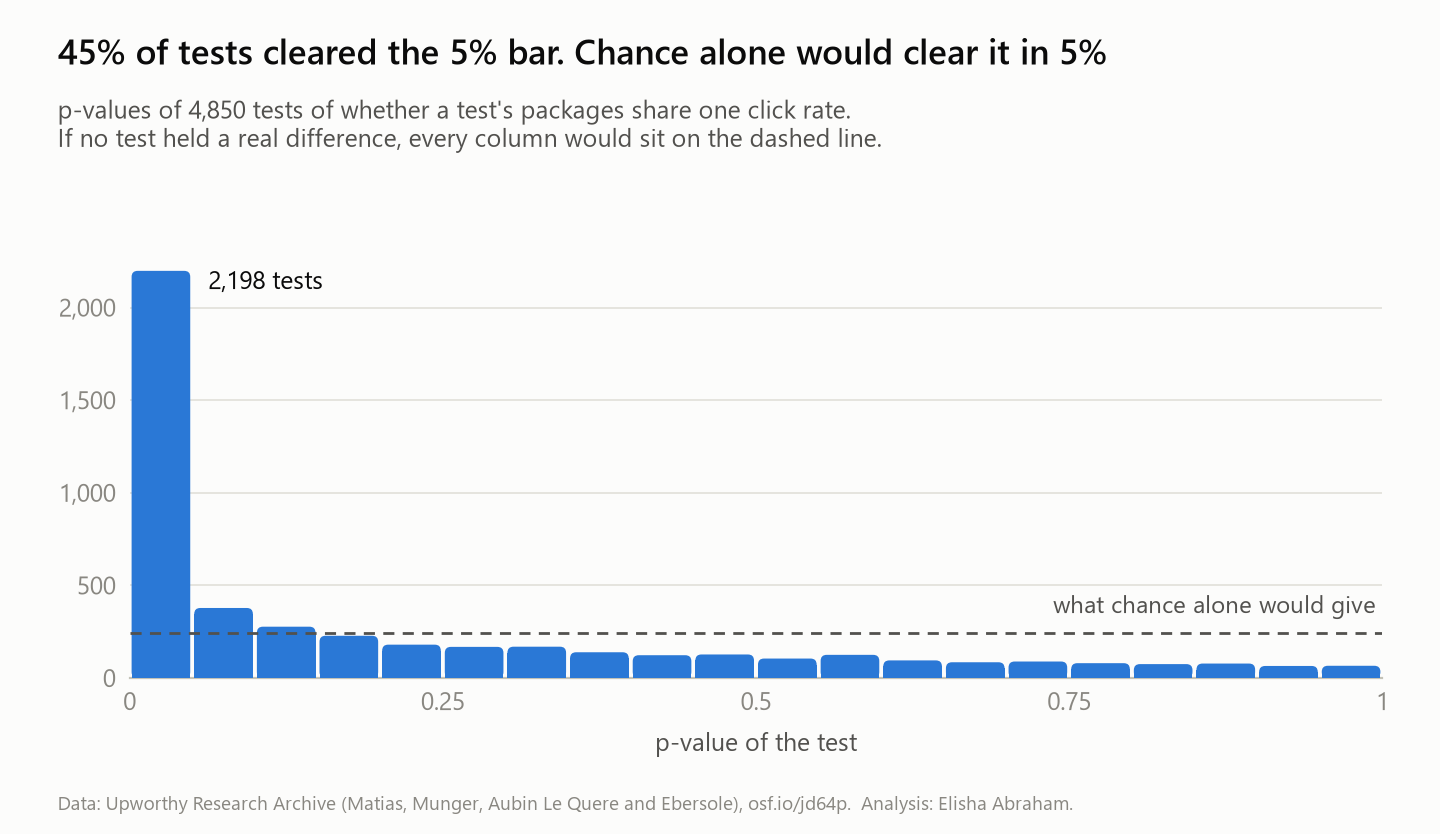

In [6]:
counts = np.histogram(p, bins=20, range=(0, 1))[0].tolist()
charts.histogram(counts, len(p) / 20,
                 f"{100 * significant.mean():.0f}% of tests cleared the 5% bar. Chance alone would clear it in 5%",
                 f"p-values of {len(p):,} tests of whether a test's packages share one click rate.\n"
                 "If no test held a real difference, every column would sit on the dashed line.",
                 FIGURES, "01_p_values", "p-value of the test", "what chance alone would give")
display(Image(filename=str(FIGURES / "01_p_values_light.png"), width=720))

Nearly half the tests clear the 5% bar, and about two-thirds are estimated to hold a real difference.
Headline tests find differences most often and teaser-text tests least. These experiments were worth
running: wording and images really did change what people clicked.

The 14 tests in which nothing recorded differs between the packages are the nearest thing the archive has
to placebo tests. There are too few of them to check the 5% false-alarm rate properly.

## 4. How big are the differences, and how much of a win is luck?

The best package in a test looks better than it is. It was picked *because* it scored highest, and part
of every score is luck. Three numbers separate the real from the lucky:

1. the **measured lift** of the best package over the average package in its test;
2. the lift the best package would show **if no package were truly better** (clicks redrawn at random,
   every package given its test's overall click rate);
3. the **expected true lift** of the best package, shrinking each measured advantage by the share of it
   that is real. That share comes from comparing how much click rates vary inside tests with how much
   they would vary from sampling noise alone.

In [7]:
spread = ab.true_spread(data)
best = ab.winners(data, spread["true_variance"])
luck = ab.lift_from_noise_alone(data)
print(f"variance of log odds inside a test: {spread['observed_variance']:.4f} measured, "
      f"{spread['noise_variance']:.4f} of it sampling noise, {spread['true_variance']:.4f} real")
print(f"so packages in the same test truly differ by a standard deviation of about {100 * spread['true_sd']:.0f}% in click rate")
print(f"measured lift of the best package (median):        {100 * best['measured_lift'].median():.1f}%")
print(f"lift of the 'best' package from luck alone (median): {100 * luck:.1f}%")
print(f"expected true lift of the best package (median):   {100 * best['expected_true_lift'].median():.1f}%")
print(f"share of a typical winner's measured advantage that is real: {100 * best['share_kept'].median():.0f}%")

variance of log odds inside a test: 0.0955 measured, 0.0359 of it sampling noise, 0.0596 real
so packages in the same test truly differ by a standard deviation of about 24% in click rate
measured lift of the best package (median):        29.9%
lift of the 'best' package from luck alone (median): 16.5%
expected true lift of the best package (median):   21.2%
share of a typical winner's measured advantage that is real: 77%


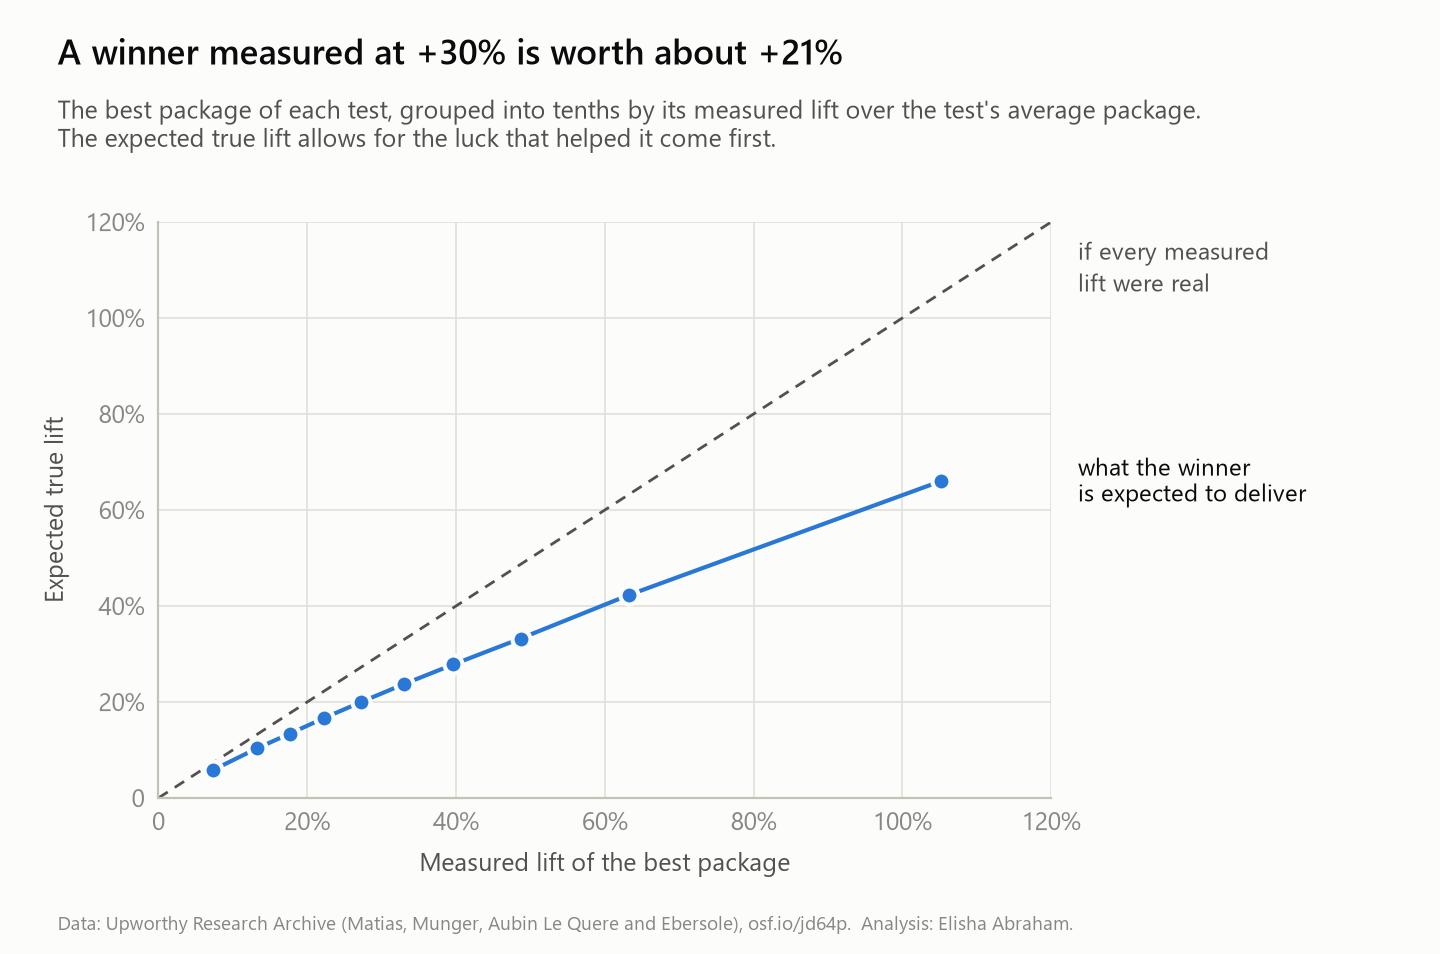

In [8]:
tenths = pd.qcut(best["measured_lift"], 10, labels=False)
points = [(100 * part["measured_lift"].mean(), 100 * part["expected_true_lift"].mean()) for _, part in best.groupby(tenths)]
limit = int(np.ceil(max(points[-1]) / 20) * 20)
charts.measured_against_true(points,
                             f"A winner measured at +{100 * best['measured_lift'].median():.0f}% is worth about "
                             f"+{100 * best['expected_true_lift'].median():.0f}%",
                             "The best package of each test, grouped into tenths by its measured lift over the test's average package.\n"
                             "The expected true lift allows for the luck that helped it come first.",
                             FIGURES, "02_winners_curse", limit, "Measured lift of the best package", "Expected true lift",
                             "what the winner\nis expected to deliver", "if every measured\nlift were real")
display(Image(filename=str(FIGURES / "02_winners_curse_light.png"), width=720))

With no real differences at all, the "best" of four or five packages would still appear to beat the
average by about a sixth. The real winners do better than that, so most of their advantage is real, but
not all of it: the bigger the measured win, the more of it is luck.

The shrinkage assumes that true differences between packages follow a normal distribution with the same
spread in every test. That is a simplification; it is used here to size the problem, not to rescore
individual tests.

## 5. Was there enough traffic?

The smallest lift a test can reliably detect depends on how many people saw each package. For a test of
two packages, 80% power and the usual 5% level:

In [9]:
traffic, rate = float(data["impressions"].median()), float(tests["ctr"].median())
detectable = ab.minimum_detectable_lift(traffic, rate)
needed = pd.DataFrame({"lift to detect, %": [5, 10, 20, 30, 50]})
needed["impressions needed per package"] = [round(ab.impressions_needed(rate, lift / 100)) for lift in needed["lift to detect, %"]]
needed["times Upworthy's typical traffic"] = (needed["impressions needed per package"] / traffic).round(1)
print(f"typical traffic: {traffic:,.0f} impressions per package at a click rate of {100 * rate:.2f}%")
print(f"smallest lift detectable 80% of the time: {100 * detectable:.0f}%")
display(needed)

typical traffic: 3,122 impressions per package at a click rate of 1.31%
smallest lift detectable 80% of the time: 72%


,"lift to detect, %",impressions needed per package,times Upworthy's typical traffic
0,5,485745,155.600
1,10,124354,39.800
2,20,32544,10.400
3,30,15110,4.800
4,50,5902,1.900


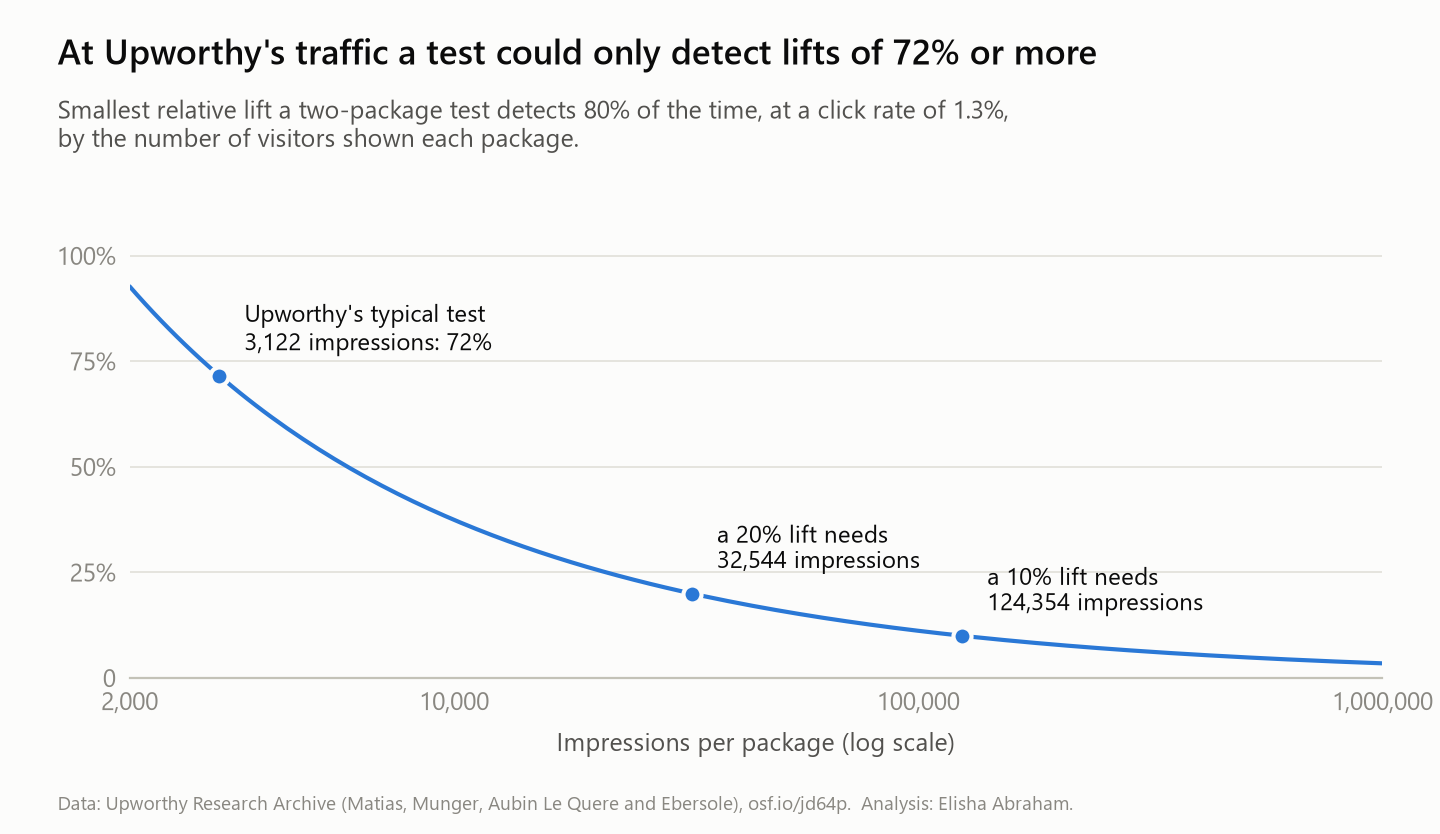

In [10]:
xs = np.geomspace(2_000, 1_000_000, 160)
ys = [100 * ab.minimum_detectable_lift(x, rate) for x in xs]
marks = [{"x": traffic, "y": 100 * detectable, "text": f"Upworthy's typical test\n{traffic:,.0f} impressions: {100 * detectable:.0f}%"},
         {"x": ab.impressions_needed(rate, 0.20), "y": 20, "text": f"a 20% lift needs\n{ab.impressions_needed(rate, 0.20):,.0f} impressions"},
         {"x": ab.impressions_needed(rate, 0.10), "y": 10, "text": f"a 10% lift needs\n{ab.impressions_needed(rate, 0.10):,.0f} impressions"}]
charts.curve(xs.tolist(), ys, marks,
             f"At Upworthy's traffic a test could only detect lifts of {100 * detectable:.0f}% or more",
             f"Smallest relative lift a two-package test detects 80% of the time, at a click rate of {100 * rate:.1f}%,\n"
             "by the number of visitors shown each package.",
             FIGURES, "03_detectable_lift", "Impressions per package (log scale)", [2_000, 10_000, 100_000, 1_000_000],
             [0, 25, 50, 75, 100])
display(Image(filename=str(FIGURES / "03_detectable_lift_light.png"), width=720))

These tests were built to find big differences, and big differences were there to find (section 4). A
team hunting for a 5% or 10% improvement with this much traffic would be running tests that cannot see
what they are looking for.

## 6. What do winning headlines have in common?

One test compares a handful of headlines for one story. Thousands of tests together can show which
*kinds* of headline tend to win. The comparison is made only inside tests, and only in tests where the
headline is the one thing that varies, so the story, the image, the day and the audience are identical
for the headlines being compared.

Each headline is described by a few countable properties. The model asks how a test's clicks were divided
among its headlines, given their properties (Poisson regression with a separate baseline for every test,
and standard errors clustered by test).

In [11]:
headline_tests = tests.index[tests["varies"] == "headline only"]
pure = data[data["test"].isin(headline_tests)].reset_index(drop=True)
features = ab.headline_features(pure["headline"])
print(f"{len(headline_tests):,} tests that vary only the headline, {len(pure):,} headlines")
share = features.drop(columns="words_per_5").mean().mul(100).round(1).rename("headlines with it, %")
display(share.rename(index=ab.FEATURES).to_frame())
print(f"median headline length: {5 * features['words_per_5'].median():.0f} words")

1,801 tests that vary only the headline, 8,324 headlines


,"headlines with it, %"
Has a question mark,17.600
Contains a number,15.800
"Says I, my or me",12.500
"Says we, our or us",11.300
"Points forward (this, these, here's)",30.100
Has an exclamation mark,2.300
Has a colon,4.400
"Speaks to the reader (you, your)",23.500
Has a quotation,1.000
Starts with a number,3.000


median headline length: 15 words


In [12]:
fit = ab.within_test_model(pure, features)
table = fit.assign(property=fit.index.map(ab.FEATURES))[["property", "ratio", "low", "high", "z", "p_value"]]
display(table.sort_values("z", key=np.abs, ascending=False).reset_index(drop=True))
print(f"clustered standard errors are {(fit['se'] / fit['model_se']).median():.1f} times the ones the model alone would give")

,property,ratio,low,high,z,p_value
0,Has a question mark,0.902,0.879,0.927,-7.484,0.000
1,Five more words,1.068,1.049,1.087,7.237,0.000
2,"Says we, our or us",0.919,0.887,0.953,-4.583,0.000
3,Has a colon,0.927,0.891,0.966,-3.665,0.000
4,Contains a number,1.063,1.029,1.098,3.658,0.000
5,Has an exclamation mark,0.895,0.842,0.951,-3.569,0.000
6,"Points forward (this, these, here's)",1.045,1.020,1.072,3.469,0.001
7,"Says I, my or me",1.037,1.006,1.070,2.306,0.021
8,Shouts (a word in capitals or *stars*),0.977,0.942,1.013,-1.264,0.206
9,"Speaks to the reader (you, your)",1.011,0.982,1.040,0.719,0.472


clustered standard errors are 2.3 times the ones the model alone would give


A ratio of 1.07 means 7% more clicks for a headline with the property than for a rival headline in the
same test without it, other properties equal. The clustered standard errors are more than twice the
model's own: without them, every one of these effects would look far more certain than it is.

**Check.** The model is written from scratch in `src/abtests.py`. On a subset small enough for a
standard library to handle, it should give the same answer as Poisson regression with one dummy
variable per test.

In [13]:
import statsmodels.api as sm

subset = pure[pure["test"].isin(pure["test"].drop_duplicates().head(300))].reset_index(drop=True)
columns = ["words_per_5", "question", "number"]
subset_features = ab.headline_features(subset["headline"])[columns]
mine = ab.within_test_model(subset, subset_features)
design = pd.concat([subset_features, pd.get_dummies(subset["test"], dtype=float)], axis=1)
reference = sm.GLM(subset["clicks"], design, family=sm.families.Poisson(), offset=np.log(subset["impressions"])).fit()
print(f"largest difference in coefficients from statsmodels: {np.abs(mine['beta'].to_numpy() - reference.params[columns].to_numpy()).max():.1e}")
print(f"largest difference in model standard errors:          {np.abs(mine['model_se'].to_numpy() - reference.bse[columns].to_numpy()).max():.1e}")

largest difference in coefficients from statsmodels: 3.3e-14
largest difference in model standard errors:          3.8e-12


## What goes forward to the confirmatory file

A property becomes a hypothesis if its effect in the model above is at least three standard errors from
zero. The direction is part of the hypothesis.

In [14]:
hypotheses = fit[fit["z"].abs() >= 3].copy()
hypotheses["property"] = hypotheses.index.map(ab.FEATURES)
hypotheses["predicted"] = np.where(hypotheses["beta"] > 0, "more clicks", "fewer clicks")
display(hypotheses[["property", "predicted", "ratio", "z"]].sort_values("z", key=np.abs, ascending=False))

summary = ab.summary(data)
summary.rename("exploratory").to_csv(RESULTS / "exploratory_summary.csv", header=True, index_label="measure")
fit.assign(property=fit.index.map(ab.FEATURES), hypothesis=fit["z"].abs() >= 3, tests=len(headline_tests)).to_csv(
    RESULTS / "exploratory_headline_model.csv", index_label="feature")
by_kind.to_csv(RESULTS / "exploratory_tests_by_kind.csv")
needed.to_csv(RESULTS / "sample_sizes.csv", index=False)
display(summary.to_frame("exploratory"))

# How far the confirmatory figure may differ and still count as a replication (see analysis_plan.md).
ALLOWED = {"Tests with an uneven traffic split, %": 3, "Tests significant at 0.05, %": 3,
           "Tests significant with the false discovery rate held at 5%, %": 3,
           "Tests estimated to hold a real difference, %": 4, "Headline-only tests significant at 0.05, %": 4,
           "Image-only tests significant at 0.05, %": 4, "Teaser-text-only tests significant at 0.05, %": 4,
           "True spread of click rates within a test (SD of log odds)": 0.02,
           "Measured lift of the best package over the test average, median %": 3,
           "Lift of the best package from luck alone, median %": 2,
           "Expected true lift of the best package, median %": 3, "Minimum detectable lift at the median traffic, %": 5}
pd.DataFrame({"exploratory": summary[list(ALLOWED)], "allowed_difference": pd.Series(ALLOWED)}).to_csv(
    RESULTS / "predictions.csv", index_label="measure")

,property,predicted,ratio,z
question,Has a question mark,fewer clicks,0.902,-7.484
words_per_5,Five more words,more clicks,1.068,7.237
first_person_plural,"Says we, our or us",fewer clicks,0.919,-4.583
colon,Has a colon,fewer clicks,0.927,-3.665
number,Contains a number,more clicks,1.063,3.658
exclamation,Has an exclamation mark,fewer clicks,0.895,-3.569
points_forward,"Points forward (this, these, here's)",more clicks,1.045,3.469


,exploratory
Tests,"4,873.000"
Packages,"22,666.000"
Median impressions per package,"3,122.000"
"Median click rate of a test, %",1.307
"Tests with an uneven traffic split, %",15.452
"Tests significant at 0.05, %",45.320
"Tests significant with the false discovery rate held at 5%, %",35.299
"Tests estimated to hold a real difference, %",64.412
"Headline-only tests significant at 0.05, %",55.618
"Image-only tests significant at 0.05, %",42.988


The numbers in this table are also predictions. If the exploratory file is a fair sample of Upworthy's
tests, the confirmatory file should give nearly the same ones.